In [162]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt , statsmodels.api as sm, warnings, seaborn as sns, datetime
warnings.filterwarnings('ignore')
from datetime import datetime

In [163]:
customers = pd.read_csv('data/customers.csv')
delivery_events = pd.read_csv('data/delivery_events.csv')
driver_monthly_metrics = pd.read_csv('data/driver_monthly_metrics.csv')
drivers = pd.read_csv('data/drivers.csv')
facilities = pd.read_csv('data/facilities.csv')
fuel_purchases = pd.read_csv('data/fuel_purchases.csv')
loads = pd.read_csv('data/loads.csv')
maintenance_records = pd.read_csv('data/maintenance_records.csv')
routes = pd.read_csv('data/routes.csv')
safety_incidents= pd.read_csv('data/safety_incidents.csv')
trailers = pd.read_csv('data/trailers.csv')
trips = pd.read_csv('data/trips.csv')
truck_utilization_metrics = pd.read_csv('data/truck_utilization_metrics.csv')
trucks = pd.read_csv('data/trucks.csv')
timenow = datetime(2026,2,19)

### 1. Which routes generate the highest profit margin after fuel costs?

calculating profit margin

In [164]:
q1 = loads.groupby('route_id')[['revenue','fuel_surcharge','accessorial_charges']].sum()

q1['profit'] = q1['revenue']-q1['fuel_surcharge']-q1['accessorial_charges']

q1.sort_values(by='profit',ascending=False).head()

,revenue,fuel_surcharge,accessorial_charges,profit
route_id,,,,
RTE00016,10069054.22,679657.45,107775,9281621.77
RTE00012,9757537.38,684042.37,102725,8970770.01
RTE00044,9979091.72,1148261.70,101825,8729005.02
RTE00046,9501202.04,765742.12,109025,8626434.92
RTE00042,9070885.01,683186.58,106725,8280973.43


In [165]:
drivers.head()

,driver_id,first_name,last_name,hire_date,termination_date,license_number,license_state,date_of_birth,home_terminal,employment_status,cdl_class,years_experience
0,DRV00001,Jennifer,Hernandez,2014-10-31,NaN,DL673510887,WA,1973-11-07,Denver,Active,A,3
1,DRV00002,William,Martin,2020-10-02,NaN,DL128955006,GA,1976-11-03,Columbus,Active,A,20
2,DRV00003,Charles,Hernandez,2021-09-21,NaN,DL523076025,NC,1970-04-06,Salt Lake City,Active,A,19
3,DRV00004,Barbara,Brown,2013-09-08,NaN,DL735540030,WA,1995-02-06,Denver,Active,A,19
4,DRV00005,Mary,Martinez,2018-12-02,NaN,DL706011277,AZ,1960-07-15,Chicago,Active,A,12


### 2. How does driver tenure correlate with fuel efficiency and on-time performance?

calculating average on-time delivery rate and average fuel efficiency 

In [166]:
driver_monthly_metrics.head()
q2_1 = driver_monthly_metrics.groupby(by='driver_id')[['on_time_delivery_rate']].mean()
driver_monthly_metrics['fuel_efficiency'] = driver_monthly_metrics['total_miles']/driver_monthly_metrics['total_fuel_gallons']
q2_2 = driver_monthly_metrics.groupby(by='driver_id')[['fuel_efficiency']].mean()

calculating tenure duration using hire date and termination date 

In [167]:
drivers['hire_date'] = pd.to_datetime(drivers['hire_date'])
drivers['termination_date'] = drivers['termination_date'].fillna('2025-12-30')
drivers['termination_date'] = pd.to_datetime(drivers['termination_date'])
drivers['employment_period'] = drivers['termination_date']-drivers['hire_date']
drivers['employment_period'] = drivers['employment_period'].dt.days
q2_0 = drivers.set_index('driver_id')['employment_period']

calculating correlation

In [168]:
tenure_corr_fuel = q2_0.corr(q2_2['fuel_efficiency'])
tenure_corr_ontime = q2_0.corr(q2_1['on_time_delivery_rate'])

print('Correlation of tenure to fuel efficiency: ',tenure_corr_fuel)
print('Correlation of tenure to ontime : ',tenure_corr_ontime)

Correlation of tenure to fuel efficiency:  0.1082250968330581
Correlation of tenure to ontime :  0.03266215349599797


Light postive correlation found between Tenure and Fuel <br>
Essentially zero correlation between Tenure and On-time-Performance

### 3. What's the optimal preventive maintenance interval to minimize total cost of ownership?

In [169]:
maintenance_records.head()

,maintenance_id,truck_id,maintenance_date,maintenance_type,odometer_reading,labor_hours,labor_cost,parts_cost,total_cost,facility_location,downtime_hours,service_description
0,MAINT00000001,TRK00085,2022-01-01,Inspection,400255,7.8,781.42,10.41,791.83,Kansas City,22.2,Emergency Inspection
1,MAINT00000002,TRK00041,2022-01-01,Tire,268041,0.9,80.91,3207.16,3288.07,Seattle,8.0,Scheduled Tire
2,MAINT00000003,TRK00090,2022-01-01,Preventive,698915,7.2,733.18,1570.57,2303.75,Miami,16.5,Routine Preventive
3,MAINT00000004,TRK00056,2022-01-02,Inspection,416522,2.8,298.80,67.48,366.28,Kansas City,34.6,Emergency Inspection
4,MAINT00000005,TRK00029,2022-01-02,Repair,179968,4.6,409.08,982.59,1391.67,Omaha,4.4,Emergency Repair


finding maintenance costs and dates

In [170]:
maintenance_records.groupby(by='maintenance_date')['total_cost'].sum()
maintenance_records['maintenance_date'] = pd.to_datetime(maintenance_records['maintenance_date']).dt.date

In [171]:
safety_incidents.head()

,incident_id,trip_id,truck_id,driver_id,incident_date,incident_type,location_city,location_state,at_fault_flag,injury_flag,vehicle_damage_cost,cargo_damage_cost,claim_amount,preventable_flag,description
0,INC00000001,TRIP00036079,TRK00006,DRV00006,2023-04-09 14:00:00,Moving Violation,Columbus,PA,True,False,12629.26,0.00,12629.26,True,Severe incident involving equipment
1,INC00000002,TRIP00032462,TRK00084,DRV00006,2023-02-19 11:00:00,Moving Violation,Columbus,NC,False,False,2700.70,14284.24,16984.94,False,Severe incident involving weather
2,INC00000003,TRIP00067583,TRK00106,DRV00119,2024-05-20 01:00:00,Customer Complaint,Seattle,OK,True,False,24302.32,0.00,24302.32,True,Minor incident involving traffic
3,INC00000004,TRIP00049128,TRK00085,DRV00134,2023-09-26 03:00:00,Equipment Damage,Kansas City,TN,True,False,4879.13,0.00,4879.13,True,Moderate incident involving equipment
4,INC00000005,TRIP00062884,TRK00014,DRV00133,2024-03-20 14:00:00,DOT Violation,Las Vegas,IN,False,False,14951.40,0.00,14951.40,False,Minor incident involving other driver


finding preventable accidents

In [172]:
safety_incidents1 = safety_incidents.copy()
preventable_incidents = safety_incidents1[safety_incidents1['preventable_flag']==True]
preventable_incidents.head()

,incident_id,trip_id,truck_id,driver_id,incident_date,incident_type,location_city,location_state,at_fault_flag,injury_flag,vehicle_damage_cost,cargo_damage_cost,claim_amount,preventable_flag,description
0,INC00000001,TRIP00036079,TRK00006,DRV00006,2023-04-09 14:00:00,Moving Violation,Columbus,PA,True,False,12629.26,0.00,12629.26,True,Severe incident involving equipment
2,INC00000003,TRIP00067583,TRK00106,DRV00119,2024-05-20 01:00:00,Customer Complaint,Seattle,OK,True,False,24302.32,0.00,24302.32,True,Minor incident involving traffic
3,INC00000004,TRIP00049128,TRK00085,DRV00134,2023-09-26 03:00:00,Equipment Damage,Kansas City,TN,True,False,4879.13,0.00,4879.13,True,Moderate incident involving equipment
6,INC00000007,TRIP00012773,TRK00007,DRV00109,2022-06-13 02:00:00,DOT Violation,Portland,TX,True,False,12589.05,28315.16,40904.21,True,Moderate incident involving traffic
10,INC00000011,TRIP00022792,TRK00007,DRV00041,2022-10-18 02:00:00,Equipment Damage,Milwaukee,NE,True,False,18252.77,0.00,18252.77,True,Severe incident involving weather


In [173]:
df_maint_raw = maintenance_records.copy()
df_incidents_raw = preventable_incidents.copy()

TOTAL_ACTIVE_ASSETS = df_maint_raw["truck_id"].nunique()
AVG_COST_PER_MAINTENANCE_EVENT = df_maint_raw["total_cost"].mean()

resampling by month to see monthly patterns and finding TCO

In [174]:
monthly_incidents = (
    df_incidents_raw.set_index("incidents_date")
    .resample("ME")["total_costs"]
    .sum()
    .reset_index()
)
monthly_maintenance = (
    df_maint_raw.set_index("maintenance_date")
    .resample("ME")["total_cost"]
    .sum()
    .reset_index()
)

df_tco = pd.merge(
    monthly_maintenance, 
    monthly_incidents, 
    left_on="maintenance_date", 
    right_on="incidents_date", 
    how="outer"
).rename(columns={
    "maintenance_date": "Date", 
    "total_cost": "Maintenance_Cost", 
    "total_costs": "Incident_Cost"
})

df_tco["Incident_Cost"] = df_tco["Incident_Cost"].fillna(0)
df_tco["Maintenance_Cost"] = df_tco["Maintenance_Cost"].fillna(0)
df_tco["Total_TCO"] = df_tco["Maintenance_Cost"] + df_tco["Incident_Cost"]

KeyError: "None of ['incidents_date'] are in the columns"

calculating the average number of days a truck goes without maintenance 

In [ ]:
x_maint = df_tco["Maintenance_Cost"].values
y_tco = df_tco["Total_TCO"].values

DAYS_IN_MONTH = 30.416
historical_events = x_maint / AVG_COST_PER_MAINTENANCE_EVENT
historical_intervals = (TOTAL_ACTIVE_ASSETS * DAYS_IN_MONTH) / historical_events

df_analysis = pd.DataFrame({
    "Interval": historical_intervals,
    "TCO": y_tco
}).sort_values(by="Interval").reset_index(drop=True)

applying LOWESS regression between interval and TCO

In [ ]:
lowess_fit = sm.nonparametric.lowess(df_analysis["TCO"], df_analysis["Interval"], frac=0.5)
curve_x_interval = lowess_fit[:, 0]
curve_y_tco = lowess_fit[:, 1]

optimal_idx = np.argmin(curve_y_tco)
optimal_days_interval = curve_x_interval[optimal_idx]
optimal_tco_val = curve_y_tco[optimal_idx]
optimal_weeks_interval = optimal_days_interval / 7.0

target_monthly_events = (TOTAL_ACTIVE_ASSETS * DAYS_IN_MONTH) / optimal_days_interval
optimal_maint_spend = target_monthly_events * AVG_COST_PER_MAINTENANCE_EVENT

print(f"Dynamically Detected Assets:     {TOTAL_ACTIVE_ASSETS} active units")
print(f"Calculated Mean Event Cost:      {AVG_COST_PER_MAINTENANCE_EVENT}")
print(f"OPTIMAL PM INTERVAL PER ASSET:   {optimal_days_interval} DAYS  ({optimal_weeks_interval} WEEKS)")
print(f"Target PM Events Required:       {target_monthly_events} services / month")
print(f"Optimal Monthly Total Spend:     {optimal_maint_spend}")
print(f"Projected Minimum TCO Floor:     {optimal_tco_val}")
print(f"\nOperational Rule: Every individual asset should undergo a comprehensive preventive maintenance cycle exactly every {int(round(optimal_days_interval))} days to minimize TCO.")

plot for demonstration 

In [ ]:
plt.figure(figsize=(9, 5))
plt.scatter(
    df_analysis["Interval"],
    df_analysis["TCO"],
    color="#1f77b4",
    zorder=3,
    label="Historical Months (Observed TCO)",
)

plt.plot(
    curve_x_interval,
    curve_y_tco,
    color="red",
    linestyle="--",
    linewidth=2,
    label="LOWESS TCO Cost Valley Model",
)

plt.axvline(
    optimal_days_interval,
    color="green",
    linestyle=":",
    linewidth=2,
    alpha=0.9,
    label=f"Optimal Cadence ({optimal_days_interval} Days)",
)
plt.scatter([optimal_days_interval], [optimal_tco_val], color="green", marker="*", s=250, zorder=5)

plt.title("Operational Optimization: Minimum TCO Tracking Interval")
plt.xlabel("Preventive Maintenance Cadence per Asset (Days between Service)")
plt.ylabel("Total Combined Cost (Maintenance + Incidents) ($)")

plt.gca().invert_xaxis() 
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


### 4. Which customers have the highest revenue-per-load and best payment terms?

In [ ]:
customers.head()

,customer_id,customer_name,customer_type,credit_terms_days,primary_freight_type,account_status,contract_start_date,annual_revenue_potential
0,CUST00001,Metro Wholesale,Dedicated,60,General,Inactive,2020-02-20,985117
1,CUST00002,National Retail,Contract,30,Retail,Active,2021-06-02,4936566
2,CUST00003,XYZ Industries,Contract,30,Consumer Goods,Active,2020-09-04,3102814
3,CUST00004,American Corp,Contract,15,Food/Beverage,Active,2020-11-29,3948027
4,CUST00005,American Distribution,Spot,45,Consumer Goods,Active,2020-02-04,3682564


In [ ]:
loads = pd.read_csv('data/loads.csv')
loads.head()

,load_id,customer_id,route_id,load_date,load_type,weight_lbs,pieces,revenue,fuel_surcharge,accessorial_charges,load_status,booking_type
0,LOAD00000001,CUST00183,RTE00019,2022-01-01,Dry Van,19178,13,3045.23,406.72,100,Completed,Spot
1,LOAD00000002,CUST00076,RTE00058,2022-01-01,Dry Van,27761,22,1224.48,98.61,0,Completed,Dedicated
2,LOAD00000003,CUST00027,RTE00048,2022-01-01,Refrigerated,35594,16,7171.12,792.88,0,Completed,Spot
3,LOAD00000004,CUST00088,RTE00013,2022-01-01,Refrigerated,33274,10,1308.20,141.33,50,Completed,Spot
4,LOAD00000005,CUST00185,RTE00020,2022-01-01,Dry Van,40257,10,3317.18,738.48,0,Completed,Spot


calculating actual_revenue and using merge to join the tables

In [ ]:
loads['actual_revenue'] = loads['revenue']-loads['fuel_surcharge']-loads['accessorial_charges']
loads = loads.merge(customers[['customer_id','credit_terms_days']],how='left',on='customer_id')
loads.head()

,load_id,customer_id,route_id,load_date,load_type,weight_lbs,pieces,revenue,fuel_surcharge,accessorial_charges,load_status,booking_type,actual_revenue,credit_terms_days
0,LOAD00000001,CUST00183,RTE00019,2022-01-01,Dry Van,19178,13,3045.23,406.72,100,Completed,Spot,2538.51,15
1,LOAD00000002,CUST00076,RTE00058,2022-01-01,Dry Van,27761,22,1224.48,98.61,0,Completed,Dedicated,1125.87,60
2,LOAD00000003,CUST00027,RTE00048,2022-01-01,Refrigerated,35594,16,7171.12,792.88,0,Completed,Spot,6378.24,30
3,LOAD00000004,CUST00088,RTE00013,2022-01-01,Refrigerated,33274,10,1308.20,141.33,50,Completed,Spot,1116.87,45
4,LOAD00000005,CUST00185,RTE00020,2022-01-01,Dry Van,40257,10,3317.18,738.48,0,Completed,Spot,2578.70,45


customer having the highest revenue-per-load and best payment terms

In [ ]:
q4_0 = loads.sort_values(by=['actual_revenue','credit_terms_days'])
q4_0[['customer_id','actual_revenue','credit_terms_days']].tail(1)

,customer_id,actual_revenue,credit_terms_days
65668,CUST00187,7381.21,15


### 5. How do seasonal patterns affect equipment utilization and revenue?

In [ ]:
facilities.head()

,facility_id,facility_name,facility_type,city,state,latitude,longitude,dock_doors,operating_hours
0,FAC00001,Houston Distribution Center,Cross-Dock,Houston,TX,29.7604,-95.3698,125,24/7
1,FAC00002,Kansas City Hub,Cross-Dock,Kansas City,MO,39.0997,-94.5786,33,7AM-7PM
2,FAC00003,Charlotte Distribution Center,Distribution Center,Charlotte,NC,35.2271,-80.8431,138,24/7
3,FAC00004,Chicago Distribution Center,Distribution Center,Chicago,IL,41.8781,-87.6298,38,8AM-5PM
4,FAC00005,Indianapolis Hub,Distribution Center,Indianapolis,IN,39.7684,-86.1581,56,8AM-5PM


In [ ]:
truck_utilization_metrics = pd.read_csv('data/truck_utilization_metrics.csv')
truck_utilization_metrics.head()

,truck_id,month,trips_completed,total_miles,total_revenue,average_mpg,maintenance_events,maintenance_cost,downtime_hours,utilization_rate
0,TRK00001,2022-01-01,22,39269,84792.02,6.78,2,4380.98,63.1,0.710
1,TRK00001,2022-02-01,27,40787,88809.05,6.23,0,0.00,0.0,0.964
2,TRK00001,2022-03-01,34,57422,120453.71,6.49,0,0.00,0.0,1.097
3,TRK00001,2022-04-01,20,34428,73531.28,6.50,2,3548.15,71.8,0.667
4,TRK00001,2022-05-01,16,20851,40791.53,6.38,1,1969.42,43.9,0.516


In [ ]:
truck_utilization_metrics['month'] = pd.to_datetime(truck_utilization_metrics['month']).dt.month
truck_utilization_metrics2 = truck_utilization_metrics.sort_values(by='month')
truck_utilization_metrics3 = truck_utilization_metrics2.groupby('month')[['month','utilization_rate','total_revenue']].mean()

,month,utilization_rate,total_revenue
month,,,
1,1.0,0.834685,79401.086341
2,2.0,0.823688,71464.013623
3,3.0,0.825569,79251.681667
4,4.0,0.835163,76817.196159
5,5.0,0.825928,79334.132971
6,6.0,0.842283,78430.943188
7,7.0,0.830022,78946.260833
8,8.0,0.832703,79160.773188
9,9.0,0.826449,75552.894130


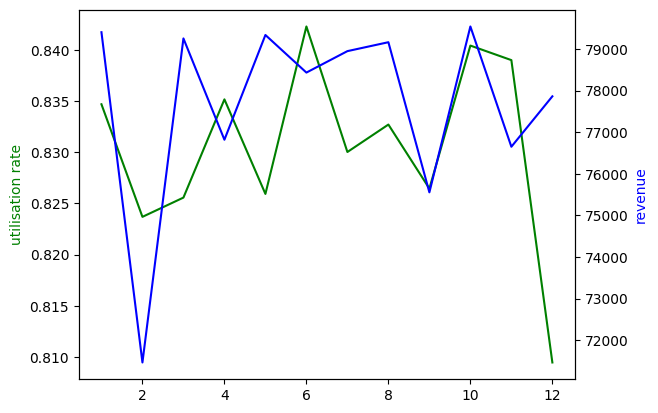

In [ ]:
fig, ax1 = plt.subplots()

ax1.plot(truck_utilization_metrics3['month'],truck_utilization_metrics3['utilization_rate'], color='green')
ax1.set_ylabel('utilisation rate',color='green')

ax2 = ax1.twinx()
ax2.plot(truck_utilization_metrics3['month'],truck_utilization_metrics3['total_revenue'], color='blue')
ax2.set_ylabel('revenue',color='blue')
plt.legend()
plt.show()

we can infer the following from the above graph:
1. there is a dip in both revenue and util_rate in the months of Feb and Nov,Dec 
2. util rate is maximum for Jun and Oct while revenue is close to maxed 5 out 12 months a year

### 6. What safety incident patterns exist by driver experience level?

In [ ]:
drivers.head()

,driver_id,first_name,last_name,hire_date,termination_date,license_number,license_state,date_of_birth,home_terminal,employment_status,cdl_class,years_experience,employment_period
0,DRV00001,Jennifer,Hernandez,2014-10-31,2025-12-30,DL673510887,WA,1973-11-07,Denver,Active,A,3,4078
1,DRV00002,William,Martin,2020-10-02,2025-12-30,DL128955006,GA,1976-11-03,Columbus,Active,A,20,1915
2,DRV00003,Charles,Hernandez,2021-09-21,2025-12-30,DL523076025,NC,1970-04-06,Salt Lake City,Active,A,19,1561
3,DRV00004,Barbara,Brown,2013-09-08,2025-12-30,DL735540030,WA,1995-02-06,Denver,Active,A,19,4496
4,DRV00005,Mary,Martinez,2018-12-02,2025-12-30,DL706011277,AZ,1960-07-15,Chicago,Active,A,12,2585


joining safety_incident tables to drivers table 

In [ ]:
safety_incidents_drivers = safety_incidents.merge(drivers[['driver_id','years_experience']],how='inner',on='driver_id')
safety_incidents_drivers.head()

,incident_id,trip_id,truck_id,driver_id,incident_date,incident_type,location_city,location_state,at_fault_flag,injury_flag,vehicle_damage_cost,cargo_damage_cost,claim_amount,preventable_flag,description,years_experience
0,INC00000001,TRIP00036079,TRK00006,DRV00006,2023-04-09 14:00:00,Moving Violation,Columbus,PA,True,False,12629.26,0.00,12629.26,True,Severe incident involving equipment,23
1,INC00000002,TRIP00032462,TRK00084,DRV00006,2023-02-19 11:00:00,Moving Violation,Columbus,NC,False,False,2700.70,14284.24,16984.94,False,Severe incident involving weather,23
2,INC00000003,TRIP00067583,TRK00106,DRV00119,2024-05-20 01:00:00,Customer Complaint,Seattle,OK,True,False,24302.32,0.00,24302.32,True,Minor incident involving traffic,6
3,INC00000004,TRIP00049128,TRK00085,DRV00134,2023-09-26 03:00:00,Equipment Damage,Kansas City,TN,True,False,4879.13,0.00,4879.13,True,Moderate incident involving equipment,18
4,INC00000005,TRIP00062884,TRK00014,DRV00133,2024-03-20 14:00:00,DOT Violation,Las Vegas,IN,False,False,14951.40,0.00,14951.40,False,Minor incident involving other driver,9


In [ ]:
safety_incidents_drivers.groupby(by='driver_id')[['preventable_flag','years_experience']].sum()

,preventable_flag,years_experience
driver_id,,
DRV00001,0,3
DRV00002,1,40
DRV00003,2,114
DRV00004,0,38
DRV00005,0,24
...,...,...
DRV00145,1,4
DRV00146,0,12
DRV00147,1,40


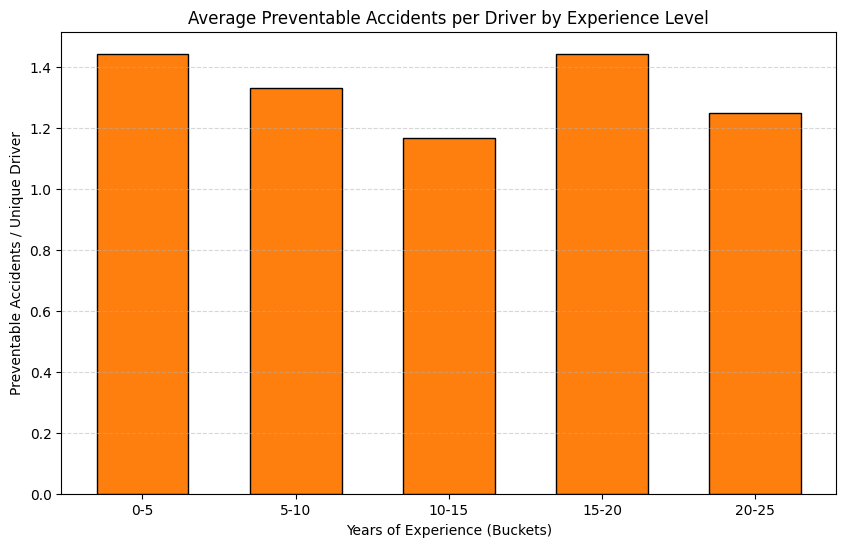

In [ ]:
preventable_df = safety_incidents_drivers[
    safety_incidents_drivers["preventable_flag"] == 1
].copy()

bin_size = 5
max_exp = preventable_df["years_experience"].max()
bins = np.arange(0, max_exp + bin_size, bin_size)

preventable_df["bucket"] = pd.cut(
    preventable_df["years_experience"], bins=bins, include_lowest=True
)

preventable_accidents = preventable_df.groupby(
    "bucket", observed=False
).size()
unique_drivers = preventable_df.groupby("bucket", observed=False)[
    "driver_id"
].nunique()

preventable_rate = preventable_accidents / unique_drivers

bin_labels = [f"{int(bins[i])}-{int(bins[i+1])}" for i in range(len(bins) - 1)]

plt.figure(figsize=(10, 6))
plt.bar(bin_labels, preventable_rate, color="#ff7f0e", edgecolor="black", width=0.6)

plt.title("Average Preventable Accidents per Driver by Experience Level")
plt.xlabel("Years of Experience (Buckets)")
plt.ylabel("Preventable Accidents / Unique Driver")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()


the drivers decrease the chances of preventable accidents by a great margin going from 0-5 years of experience to 10-15 years

### 7. Which city pairs have the most reliable on-time delivery performance?

In [ ]:
delivery_events.head()

,event_id,load_id,trip_id,event_type,facility_id,scheduled_datetime,actual_datetime,detention_minutes,on_time_flag,location_city,location_state
0,EVT00000001,LOAD00000001,TRIP00000001,Pickup,FAC00034,2022-01-01 18:00:00.000000,2022-01-01 20:58:55.918185,0,False,Houston,TX
1,EVT00000002,LOAD00000001,TRIP00000001,Delivery,FAC00046,2022-01-02 23:10:55.918185,2022-01-02 21:30:22.142060,230,True,Detroit,MI
2,EVT00000003,LOAD00000002,TRIP00000002,Pickup,FAC00015,2022-01-01 18:00:00.000000,2022-01-01 17:37:26.608430,62,True,Kansas City,MO
3,EVT00000004,LOAD00000002,TRIP00000002,Delivery,FAC00050,2022-01-02 02:13:26.608430,2022-01-02 05:55:46.238257,67,False,Indianapolis,IN
4,EVT00000005,LOAD00000003,TRIP00000003,Pickup,FAC00001,2022-01-01 08:00:00.000000,2022-01-01 07:28:02.169634,83,True,Columbus,OH


In [ ]:
routes.head()

,route_id,origin_city,origin_state,destination_city,destination_state,typical_distance_miles,base_rate_per_mile,fuel_surcharge_rate,typical_transit_days
0,RTE00001,Atlanta,GA,Chicago,IL,677,1.70,0.19,1
1,RTE00002,Atlanta,GA,Miami,FL,697,2.08,0.22,1
2,RTE00003,Chicago,IL,Los Angeles,CA,2003,2.55,0.29,3
3,RTE00004,Chicago,IL,Portland,OR,2017,1.84,0.19,3
4,RTE00005,Chicago,IL,Las Vegas,NV,1749,2.41,0.26,3


In [ ]:
loads.head()

,load_id,customer_id,route_id,load_date,load_type,weight_lbs,pieces,revenue,fuel_surcharge,accessorial_charges,load_status,booking_type,actual_revenue,credit_terms_days
0,LOAD00000001,CUST00183,RTE00019,2022-01-01,Dry Van,19178,13,3045.23,406.72,100,Completed,Spot,2538.51,15
1,LOAD00000002,CUST00076,RTE00058,2022-01-01,Dry Van,27761,22,1224.48,98.61,0,Completed,Dedicated,1125.87,60
2,LOAD00000003,CUST00027,RTE00048,2022-01-01,Refrigerated,35594,16,7171.12,792.88,0,Completed,Spot,6378.24,30
3,LOAD00000004,CUST00088,RTE00013,2022-01-01,Refrigerated,33274,10,1308.20,141.33,50,Completed,Spot,1116.87,45
4,LOAD00000005,CUST00185,RTE00020,2022-01-01,Dry Van,40257,10,3317.18,738.48,0,Completed,Spot,2578.70,45


joining tables to get the origin and destination cities from routes table

In [ ]:
delivery_event_city = delivery_events.merge(loads[['load_id','route_id']],how='left',on='load_id').merge(routes[['route_id','origin_city','destination_city']],how='left',on='route_id')
delivery_event_city.head()

,event_id,load_id,trip_id,event_type,facility_id,scheduled_datetime,actual_datetime,detention_minutes,on_time_flag,location_city,location_state,route_id,origin_city,destination_city
0,EVT00000001,LOAD00000001,TRIP00000001,Pickup,FAC00034,2022-01-01 18:00:00.000000,2022-01-01 20:58:55.918185,0,False,Houston,TX,RTE00019,Houston,Detroit
1,EVT00000002,LOAD00000001,TRIP00000001,Delivery,FAC00046,2022-01-02 23:10:55.918185,2022-01-02 21:30:22.142060,230,True,Detroit,MI,RTE00019,Houston,Detroit
2,EVT00000003,LOAD00000002,TRIP00000002,Pickup,FAC00015,2022-01-01 18:00:00.000000,2022-01-01 17:37:26.608430,62,True,Kansas City,MO,RTE00058,Kansas City,Indianapolis
3,EVT00000004,LOAD00000002,TRIP00000002,Delivery,FAC00050,2022-01-02 02:13:26.608430,2022-01-02 05:55:46.238257,67,False,Indianapolis,IN,RTE00058,Kansas City,Indianapolis
4,EVT00000005,LOAD00000003,TRIP00000003,Pickup,FAC00001,2022-01-01 08:00:00.000000,2022-01-01 07:28:02.169634,83,True,Columbus,OH,RTE00048,Columbus,Portland


In [ ]:
delivery_event_city.groupby(by=['origin_city','destination_city'])['on_time_flag'].mean().sort_values().tail(1)

origin_city  destination_city
Las Vegas    Los Angeles         0.571945
Name: on_time_flag, dtype: float64

Las Vegas <-> Los Angeles have the most reliable on-time delivery performance

### 8. How does truck age impact maintenance costs and downtime?

In [ ]:
trucks.head()

,truck_id,unit_number,make,model_year,vin,acquisition_date,acquisition_mileage,fuel_type,tank_capacity_gallons,status,home_terminal
0,TRK00001,3463,Peterbilt,2016,1VV205190335317039,2017-04-27,18814,Diesel,200,Active,Omaha
1,TRK00002,6461,Kenworth,2015,1NV753749606229960,2018-10-04,26795,Diesel,150,Active,Seattle
2,TRK00003,2335,Peterbilt,2018,1NT803101860493229,2020-09-17,11795,Diesel,150,Maintenance,Atlanta
3,TRK00004,3317,Freightliner,2015,1VV131945381692351,2017-06-17,8875,Diesel,200,Active,Salt Lake City
4,TRK00005,6731,Freightliner,2016,1FT822215709701985,2021-10-08,42042,Diesel,250,Maintenance,Miami


In [ ]:
truck_utilization_metrics.head()

,truck_id,month,trips_completed,total_miles,total_revenue,average_mpg,maintenance_events,maintenance_cost,downtime_hours,utilization_rate
0,TRK00001,1,22,39269,84792.02,6.78,2,4380.98,63.1,0.710
1,TRK00001,2,27,40787,88809.05,6.23,0,0.00,0.0,0.964
2,TRK00001,3,34,57422,120453.71,6.49,0,0.00,0.0,1.097
3,TRK00001,4,20,34428,73531.28,6.50,2,3548.15,71.8,0.667
4,TRK00001,5,16,20851,40791.53,6.38,1,1969.42,43.9,0.516


In [ ]:
truck_age = truck_utilization_metrics.merge(trucks[['truck_id','acquisition_date']],how='left',on='truck_id')
truck_age.head()

,truck_id,month,trips_completed,total_miles,total_revenue,average_mpg,maintenance_events,maintenance_cost,downtime_hours,utilization_rate,acquisition_date
0,TRK00001,1,22,39269,84792.02,6.78,2,4380.98,63.1,0.710,2017-04-27
1,TRK00001,2,27,40787,88809.05,6.23,0,0.00,0.0,0.964,2017-04-27
2,TRK00001,3,34,57422,120453.71,6.49,0,0.00,0.0,1.097,2017-04-27
3,TRK00001,4,20,34428,73531.28,6.50,2,3548.15,71.8,0.667,2017-04-27
4,TRK00001,5,16,20851,40791.53,6.38,1,1969.42,43.9,0.516,2017-04-27


In [ ]:
truck_age['time_owned'] = (timenow - pd.to_datetime(truck_age['acquisition_date'])).dt.days
truck_age

,truck_id,month,trips_completed,total_miles,total_revenue,average_mpg,maintenance_events,maintenance_cost,downtime_hours,utilization_rate,acquisition_date,time_owned
0,TRK00001,1,22,39269,84792.02,6.78,2,4380.98,63.1,0.710,2017-04-27,3220
1,TRK00001,2,27,40787,88809.05,6.23,0,0.00,0.0,0.964,2017-04-27,3220
2,TRK00001,3,34,57422,120453.71,6.49,0,0.00,0.0,1.097,2017-04-27,3220
3,TRK00001,4,20,34428,73531.28,6.50,2,3548.15,71.8,0.667,2017-04-27,3220
4,TRK00001,5,16,20851,40791.53,6.38,1,1969.42,43.9,0.516,2017-04-27,3220
...,...,...,...,...,...,...,...,...,...,...,...,...
3307,TRK00120,8,15,19931,47939.96,6.29,1,861.08,47.3,0.484,2019-03-06,2542
3308,TRK00120,9,20,29583,64748.71,6.53,0,0.00,0.0,0.667,2019-03-06,2542
3309,TRK00120,10,20,22229,49688.65,6.48,4,7341.49,131.9,0.645,2019-03-06,2542
3310,TRK00120,11,25,38435,78366.23,6.39,1,1845.34,38.0,0.833,2019-03-06,2542


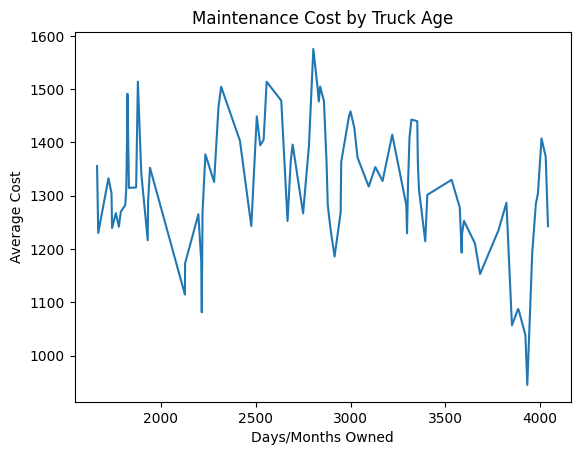

In [ ]:
age_trends = truck_age.groupby('time_owned')[['maintenance_cost', 'downtime_hours']].mean().reset_index()

age_trends['smoothed_cost'] = age_trends['maintenance_cost'].rolling(window=5, min_periods=1).mean()
age_trends['smoothed_downtime'] = age_trends['downtime_hours'].rolling(window=5, min_periods=1).mean()

plt.plot(age_trends['time_owned'], age_trends['smoothed_cost'])
plt.title('Maintenance Cost by Truck Age')
plt.xlabel('Days/Months Owned')
plt.ylabel('Average Cost')
plt.show()


maintenance cost has effectively plateaued w.r.t. the age of the vehicle 

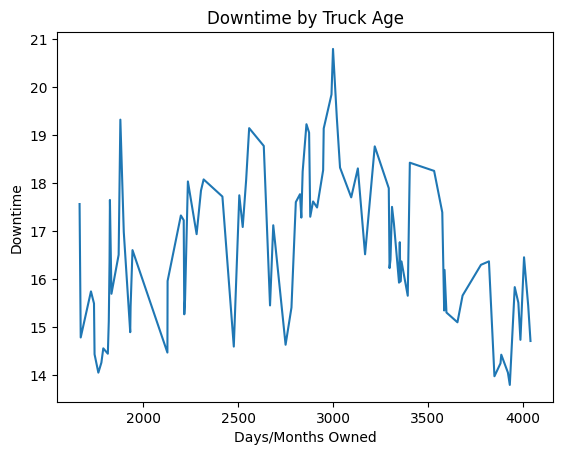

In [ ]:
plt.plot(age_trends['time_owned'], age_trends['smoothed_downtime'])
plt.title('Downtime by Truck Age')
plt.xlabel('Days/Months Owned')
plt.ylabel('Downtime')
plt.show()


downtime has a hump like trajectory with it increasing until mid-life of the vehicle, after which it decreases back down 

### The End